# Vaccination Coverage vs. Respiratory Hospitalizations in Washington State
Chris McCarthy

DSC 680-T301

Final Project

This notebook compares seasonal vaccination coverage (WA DOH Respiratory Immunization Data, from WAIIS) with lab-confirmed hospitalization rates (WA DOH Respiratory Illness Data Dashboard, from WA RESP-NET) for COVID-19, influenza and RSV. It covers the 2024-25 and 2025-26 seasons.

The design is ecological: both sources are group-level summaries, so every result describes groups (race/ethnicity, age bands, counties), not individuals.

## 1. Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneGroupOut
from matplotlib.ticker import FuncFormatter, LogLocator

DATA_DIR = "data/raw" if os.path.isdir("data/raw") else "."
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

SEASONS = ["2024-2025", "2025-2026"]          # the two complete seasons in both sources
#colorblind friendly palette
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SEASON_COLOR = {"2024-2025": C_BLUE, "2025-2026": C_ORANGE}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "figure.dpi": 110,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

def path(name):
    return os.path.join(DATA_DIR, name)

The scatter-plot helper below is used for Figures 2, 3 and 4. `nudge` moves a label (in points) when two labels would overlap.

In [2]:
def scatter_panel(ax, d, title, logy=True, nudge=None):
    nudge = nudge or {}
    for lab, g in d.groupby("label"):
        g = g.sort_values("season")
        ax.plot(g["coverage"], g["season_rate"], color=GRID, lw=1.5, zorder=2)
    for season in SEASONS:
        s = d[d["season"] == season]
        ax.scatter(s["coverage"], s["season_rate"], s=55, color=SEASON_COLOR[season],
                   edgecolor="white", linewidth=1.5, zorder=3, label=season.replace("-20", "-"))
    latest = d[d["season"] == SEASONS[1]]
    for _, r in latest.iterrows():
        ax.annotate(r["label"], (r["coverage"], r["season_rate"]), textcoords="offset points",
                    xytext=nudge.get(r["label"], (5, -3)), fontsize=8, color=INK2)
    if logy:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=()))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title(title, loc="left", fontsize=10.5, color=INK)
    ax.set_xlabel("Percent vaccinated")

## 2. Load and clean the vaccination coverage tables

Each DOH coverage file is a small wide table: one row per group, one column per season, plus a trailing "Data as of" footer row. The function below removes the footer, reshapes to long format and converts percentages to numbers. Blank cells (DOH suppresses small counties) become missing values and are not imputed.

In [3]:
def load_coverage(file_name, vaccine, dimension):
    raw = pd.read_csv(path(file_name))
    first = raw.columns[0]
    raw = raw[~raw[first].astype(str).str.startswith("Data as of")]
    long = raw.melt(id_vars=first, var_name="column", value_name="coverage_raw")
    long["season"] = long["column"].str[-9:]
    long["coverage"] = pd.to_numeric(long["coverage_raw"].astype(str).str.rstrip("%"), errors="coerce")
    long = long.rename(columns={first: "group"})
    long["vaccine"] = vaccine
    long["dimension"] = dimension
    return long[["vaccine", "dimension", "group", "season", "coverage"]]

coverage_files = [
    ("COVID-19Table2CoverageByCounty.csv", "COVID-19", "County"),
    ("COVID-19Table3CoverageByRaceEthnicity.csv", "COVID-19", "Race/Ethnicity"),
    ("COVID-19Table4CoverageByAgeGroup.csv", "COVID-19", "Age"),
    ("COVID-19Table5CoverageBySex.csv", "COVID-19", "Sex"),
    ("FluTable2CoverageByCounty.csv", "Influenza", "County"),
    ("FluTable3CoverageByRaceEthnicity.csv", "Influenza", "Race/Ethnicity"),
    ("FluTable4CoverageByAgeGroup.csv", "Influenza", "Age"),
    ("FluTable5CoverageBySex.csv", "Influenza", "Sex"),
    ("AdultRSVTable3CoverageByRaceEthnicity.csv", "RSV adult 75+", "Race/Ethnicity"),
    ("AdultRSVTable4CoverageBySex.csv", "RSV adult 75+", "Sex"),
    ("PediatricRSVTable2CoveragebyCounty.csv", "RSV pediatric", "County"),
    ("PediatricRSVTable3CoverageByRaceEthnicity.csv", "RSV pediatric", "Race/Ethnicity"),
    ("PediatricRSVTable4CoverageBySex.csv", "RSV pediatric", "Sex"),
]
coverage = pd.concat([load_coverage(*f) for f in coverage_files], ignore_index=True)
print("Coverage rows:", len(coverage))
print("Missing (suppressed) coverage values:", coverage["coverage"].isna().sum())
print("Duplicate rows:", coverage.duplicated(["vaccine", "dimension", "group", "season"]).sum())
coverage.head()

Coverage rows: 653
Missing (suppressed) coverage values: 14
Duplicate rows: 0


,vaccine,dimension,group,season,coverage
0,COVID-19,County,Adams,2023-2024,3.6
1,COVID-19,County,Asotin,2023-2024,9.7
2,COVID-19,County,Benton,2023-2024,11.2
3,COVID-19,County,Chelan,2023-2024,13.1
4,COVID-19,County,Clallam,2023-2024,24.3


The adult RSV county file on the DOH site is empty, so adult RSV has no county table. Pediatric RSV has no 2026-27 county column yet.

In [4]:
statewide = (coverage[(coverage["dimension"] == "Race/Ethnicity") & (coverage["group"] == "Statewide")]
             .pivot(index="season", columns="vaccine", values="coverage"))
statewide

vaccine,COVID-19,Influenza,RSV adult 75+,RSV pediatric
season,,,,
2023-2024,19.6,31.2,29.1,20.2
2024-2025,18.8,30.0,39.2,40.6
2025-2026,15.3,29.1,44.7,43.4
2026-2027,11.2,21.1,46.5,22.2


## 3. Load and clean the hospitalization data (RESP-NET)

Same preparation as Project 1 so the two projects stay comparable and consistent:
keep the rate metric (not the confidence limits), keep the two complete seasons, drop "Combined conditions", and summarize each season as the **mean of the weekly 4-week rates per 100,000**. Missing weeks (early-season weeks without four weeks of data, small summer counts) are left out of the mean without imputation.

This is not a cumulative seasonal rate. The number of available weeks may vary by group and season, which can affect comparisons.

In [5]:
hosp_raw = pd.read_csv(path("respiratory_hospitalizations_downloadable.csv"))
print("Raw rows:", len(hosp_raw), "| DOH update:", hosp_raw["Date Updated"].iloc[0])

h = hosp_raw[hosp_raw["Metric"].str.contains("Per 100,000")
             & hosp_raw["Season"].isin(SEASONS)
             & (hosp_raw["Condition"] != "Combined conditions")].copy()
h = h.rename(columns={"Condition": "illness", "Location": "location", "Season": "season",
                      "Demographic Category": "category", "Demographic": "group", "Values": "rate"})
print("Rate rows kept:", len(h), "| missing weekly rates:", h["rate"].isna().sum())

hosp = (h.groupby(["location", "season", "illness", "category", "group"])["rate"]
          .agg(season_rate="mean", weeks="count").reset_index())
hosp.head()

Raw rows: 58644 | DOH update: 2026-10-13 16:27:30 PM
Rate rows kept: 10395 | missing weekly rates: 1591


,location,season,illness,category,group,season_rate,weeks
0,Benton County,2024-2025,COVID-19,Overall,All,1.719388,49
1,Benton County,2024-2025,Influenza,Overall,All,3.823571,28
2,Benton County,2024-2025,RSV,Overall,All,0.665510,49
3,Benton County,2025-2026,COVID-19,Overall,All,0.739623,53
4,Benton County,2025-2026,Influenza,Overall,All,1.764808,52


## 4. Build matched analysis tables

The two sources use different group definitions, so each comparison needs an explicit mapping.

Statewide demographic coverage is matched to hospitalization rates from the eight RESP-NET counties, not the entire state. This geographic mismatch limits interpretation.

### 4a. Race/ethnicity

Coverage lists Hispanic as its own category next to the race groups. RESP-NET reports race and Hispanic ethnicity separately (age-adjusted). I match the five shared race groups by name and match coverage "Hispanic" to the RESP-NET Hispanic ethnicity rate. RESP-NET's "Multiple races" has no coverage match and is dropped. Because the Hispanic match crosses two classification systems, the six-group analysis is primary and results without Hispanic are a sensitivity check.

In [6]:
RACE_MAP = {"American Indian/Alaska Native": "American Indian Alaska Native",
            "Native Hawaiian/Pacific Islander": "Native Hawaiian Pacific Islander"}
SHORT = {"American Indian Alaska Native": "AI/AN", "Asian": "Asian", "Black": "Black",
         "Hispanic": "Hispanic", "Native Hawaiian Pacific Islander": "NH/PI", "White": "White"}
VAX_TO_ILLNESS = {"COVID-19": "COVID-19", "Influenza": "Influenza",
                  "RSV adult 75+": "RSV", "RSV pediatric": "RSV"}

resp = hosp[hosp["location"] == "RESP-NET Counties"]


cov_race = coverage[(coverage["dimension"] == "Race/Ethnicity") & (coverage["group"] != "Statewide")].copy()
cov_race["group"] = cov_race["group"].replace(RACE_MAP)
cov_race["illness"] = cov_race["vaccine"].map(VAX_TO_ILLNESS)
race = cov_race.merge(resp[resp["category"].isin(["Race", "Ethnicity"])],
                      on=["illness", "season", "group"], how="inner")
race["label"] = race["group"].map(SHORT)
race = race[["vaccine", "illness", "season", "label", "coverage", "season_rate", "weeks"]]
print("Race rows:", len(race))
race[race["vaccine"] == "Influenza"].round(2)

Race rows: 48


,vaccine,illness,season,label,coverage,season_rate,weeks
12,Influenza,Influenza,2024-2025,AI/AN,28.1,3.86,28
13,Influenza,Influenza,2024-2025,Asian,34.6,1.70,28
14,Influenza,Influenza,2024-2025,Black,23.4,6.01,28
15,Influenza,Influenza,2024-2025,Hispanic,19.6,2.34,28
16,Influenza,Influenza,2024-2025,NH/PI,24.3,11.58,28
17,Influenza,Influenza,2024-2025,White,28.9,2.88,28
18,Influenza,Influenza,2025-2026,AI/AN,26.7,1.22,52
19,Influenza,Influenza,2025-2026,Asian,34.3,0.71,52
20,Influenza,Influenza,2025-2026,Black,22.5,2.15,52
21,Influenza,Influenza,2025-2026,Hispanic,18.1,1.06,52


### 4b. Age

Coverage bands are 6m-4, 5-12, 13-17, 18-24, 25-34, 35-49, 50-64, 65+. RESP-NET bands are 0-4, 5-17, 18-49, 50-64, 65+. Where coverage bands must be combined I weight them by the number of birth years in each band (for example 5-12 = 8 years, 13-17 = 5). This is an approximation, not population weighting. Actual population sizes by age may differ. The youngest coverage band also excludes infants under six months.

In [7]:
AGE_WEIGHTS = {
    "Age 0-4":   {"6m-4 years": 1},
    "Age 5-17":  {"5-12 years": 8, "13-17 years": 5},
    "Age 18-49": {"18-24 years": 7, "25-34 years": 10, "35-49 years": 15},
    "Age 50-64": {"50-64 years": 1},
    "Age 65+":   {"65+ years": 1},
}
cov_age = coverage[coverage["dimension"] == "Age"].set_index(["vaccine", "season", "group"])["coverage"]
age_rows = []
for vax in ["COVID-19", "Influenza"]:
    for season in SEASONS:
        for band, parts in AGE_WEIGHTS.items():
            weighted_total = 0
            total_weight = 0
            for group, weight in parts.items():
                weighted_total += cov_age[(vax, season, group)] * weight
                total_weight += weight
            cov_val = weighted_total / total_weight
            r = resp[(resp["illness"] == vax) & (resp["season"] == season) & (resp["group"] == band)]
            age_rows.append({"vaccine": vax, "season": season, "label": band.replace("Age ", ""),
                             "coverage": cov_val, "season_rate": r["season_rate"].iloc[0]})
age = pd.DataFrame(age_rows)
print("Age rows:", len(age))
age.round(2)

Age rows: 20


,vaccine,season,label,coverage,season_rate
0,COVID-19,2024-2025,0-4,14.20,0.91
1,COVID-19,2024-2025,5-17,9.97,0.12
2,COVID-19,2024-2025,18-49,11.99,0.45
3,COVID-19,2024-2025,50-64,20.90,1.20
4,COVID-19,2024-2025,65+,42.40,6.71
5,COVID-19,2025-2026,0-4,11.20,0.43
6,COVID-19,2025-2026,5-17,7.28,0.09
7,COVID-19,2025-2026,18-49,9.78,0.22
8,COVID-19,2025-2026,50-64,15.90,0.51
9,COVID-19,2025-2026,65+,35.80,2.69


### 4c. County

The 8 RESP-NET counties have overall (all-age) rates only, matched to county coverage by name.

In [8]:
cov_cty = coverage[coverage["dimension"] == "County"].copy()
cov_cty["location"] = cov_cty["group"] + " County"
cov_cty["illness"] = cov_cty["vaccine"].map(VAX_TO_ILLNESS)
county = cov_cty.merge(hosp[hosp["category"] == "Overall"].drop(columns="group"),
                       on=["location", "season", "illness"])
county["label"] = county["group"]
county = county[["vaccine", "illness", "season", "label", "coverage", "season_rate"]]
print("County rows:", len(county))

County rows: 48


## 5. Statewide coverage trend (Figure 1)

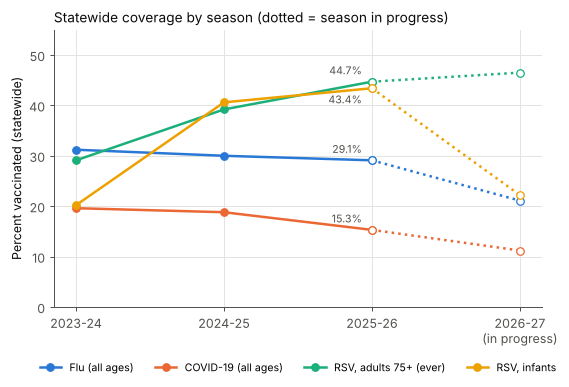

In [9]:
order = ["2023-2024", "2024-2025", "2025-2026", "2026-2027"]
fig, ax = plt.subplots(figsize=(7, 4))
lines = [("Influenza", C_BLUE, "Flu (all ages)"), ("COVID-19", C_ORANGE, "COVID-19 (all ages)"),
         ("RSV adult 75+", C_AQUA, "RSV, adults 75+ (ever)"), ("RSV pediatric", C_YELLOW, "RSV, infants")]
x = np.arange(len(order))
for vax, col, name in lines:
    y = statewide.loc[order, vax].values
    ax.plot(x[:3], y[:3], color=col, lw=2, marker="o", ms=6, label=name)
    ax.plot(x[2:], y[2:], color=col, lw=2, ls=":", marker="o", ms=6, mfc="white")
    off = {"RSV adult 75+": (-8, 6), "RSV pediatric": (-8, -12)}.get(vax, (-8, 6))
    ax.annotate(f"{y[2]:.1f}%", (x[2], y[2]), textcoords="offset points", xytext=off,
                ha="right", fontsize=8.5, color=INK2)
ax.set_xticks(x, ["2023-24", "2024-25", "2025-26", "2026-27\n(in progress)"])
ax.set_ylabel("Percent vaccinated (statewide)")
ax.set_ylim(0, 55)
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
ax.set_title("Statewide coverage by season (dotted = season in progress)", loc="left", fontsize=11, color=INK)
fig.savefig(f"{FIG_DIR}/fig1_statewide_coverage.png")
plt.show()

## 6. Research question 1 and 2: coverage vs. hospitalization by race/ethnicity

Method: Spearman rank correlation within each vaccine and season (6 groups each). With only six groups, I report descriptive correlation coefficients rather than formal significance tests and check whether the direction is consistent across seasons. I also report Pearson correlation on the log rate, because hospitalization rates are skewed by one very high group (NH/PI).

In [10]:
def corr_table(df):
    rows = []
    for (vaccine, season), d in df.groupby(["vaccine", "season"]):
        d = d.dropna(subset=["coverage", "season_rate"])
        d = d[d["season_rate"] > 0]  # log requires positive rates
        rho = np.nan
        r_log = np.nan
        if len(d) >= 2 and d["coverage"].nunique() > 1 and d["season_rate"].nunique() > 1:
            rho = spearmanr(d["coverage"], d["season_rate"])[0]
            r_log = pearsonr(d["coverage"], np.log(d["season_rate"]))[0]
        rows.append({"vaccine": vaccine, "season": season, "n": len(d),
                     "spearman": round(rho, 2), "pearson_log": round(r_log, 2)})
    return pd.DataFrame(rows)

race_corr = corr_table(race)
race_corr_no_hisp = corr_table(race[race["label"] != "Hispanic"])
print("All six groups")
print(race_corr.to_string(index=False))
print("\nSensitivity: Hispanic removed")
print(race_corr_no_hisp.to_string(index=False))

All six groups
      vaccine    season  n  spearman  pearson_log
     COVID-19 2024-2025  6     -0.20        -0.38
     COVID-19 2025-2026  6     -0.31        -0.42
    Influenza 2024-2025  6     -0.37        -0.43
    Influenza 2025-2026  6     -0.37        -0.49
RSV adult 75+ 2024-2025  6      0.37         0.54
RSV adult 75+ 2025-2026  6      0.49         0.67
RSV pediatric 2024-2025  6     -0.31        -0.30
RSV pediatric 2025-2026  6      0.03        -0.05

Sensitivity: Hispanic removed
      vaccine    season  n  spearman  pearson_log
     COVID-19 2024-2025  5      -0.7        -0.89
     COVID-19 2025-2026  5      -0.9        -0.78
    Influenza 2024-2025  5      -0.9        -0.90
    Influenza 2025-2026  5      -0.9        -0.86
RSV adult 75+ 2024-2025  5       0.4         0.54
RSV adult 75+ 2025-2026  5       0.3         0.67
RSV pediatric 2024-2025  5      -0.3        -0.33
RSV pediatric 2025-2026  5       0.1        -0.12


Figure 2 plots the same race/ethnicity comparison.

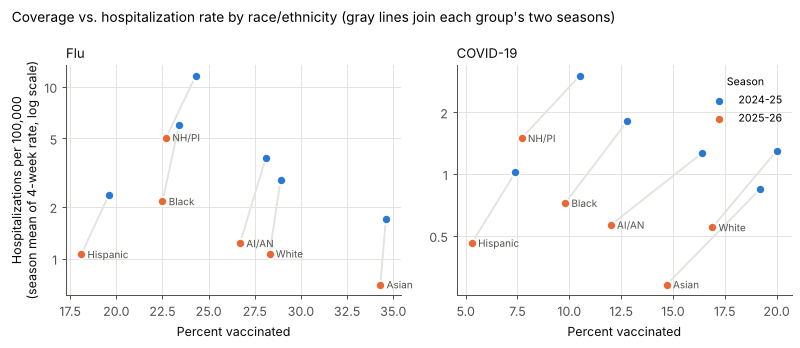

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
scatter_panel(axes[0], race[race["vaccine"] == "Influenza"], "Flu")
scatter_panel(axes[1], race[race["vaccine"] == "COVID-19"], "COVID-19")
axes[0].set_ylabel("Hospitalizations per 100,000\n(season mean of 4-week rate, log scale)")
axes[1].legend(frameon=False, fontsize=8.5, title="Season", title_fontsize=8.5)
fig.suptitle("Coverage vs. hospitalization rate by race/ethnicity (gray lines join each group's two seasons)", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig2_race_scatter.png")
plt.show()

RSV is shown separately because neither RSV coverage measure covers the whole population that the all-ages RSV hospitalization rate counts (adult coverage is adults 75+ ever vaccinated; pediatric coverage is infants).

In [12]:
print(race_corr[race_corr["vaccine"].str.startswith("RSV")].to_string(index=False))

      vaccine    season  n  spearman  pearson_log
RSV adult 75+ 2024-2025  6      0.37         0.54
RSV adult 75+ 2025-2026  6      0.49         0.67
RSV pediatric 2024-2025  6     -0.31        -0.30
RSV pediatric 2025-2026  6      0.03        -0.05


## 7. Research question 4: age confounding (Figure 3)

Older adults are both the most vaccinated and the most hospitalized group, so comparing across age bands should produce a *positive* association even if vaccines protect people. This pattern is consistent with age confounding, but does not establish individual vaccine effectiveness. The figure title summarizes the hypothesized mechanism, not a causal result established by this analysis.

  vaccine    season  n  spearman  pearson_log
 COVID-19 2024-2025  5       1.0         0.91
 COVID-19 2025-2026  5       1.0         0.94
Influenza 2024-2025  5       0.8         0.92
Influenza 2025-2026  5       1.0         0.98


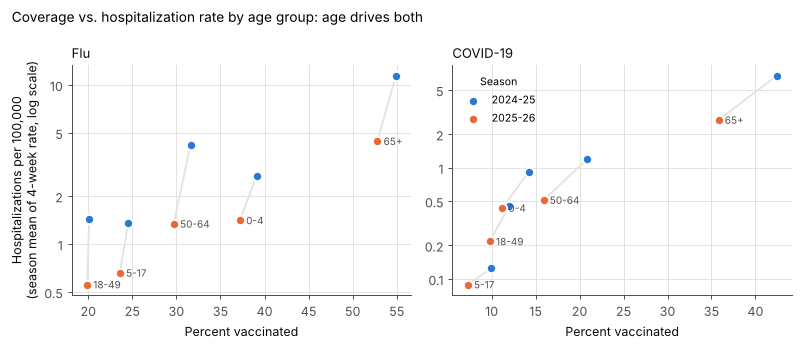

In [13]:
age_corr = corr_table(age)
print(age_corr.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
scatter_panel(axes[0], age[age["vaccine"] == "Influenza"], "Flu")
scatter_panel(axes[1], age[age["vaccine"] == "COVID-19"], "COVID-19")
axes[0].set_ylabel("Hospitalizations per 100,000\n(season mean of 4-week rate, log scale)")
axes[1].legend(frameon=False, fontsize=8.5, title="Season", title_fontsize=8.5)
fig.suptitle("Coverage vs. hospitalization rate by age group: age drives both",
             x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig3_age_confounding.png")
plt.show()

## 8. County comparison (Figure 4)

County rates are all ages and not age-adjusted, so differences in county age structure are mixed in with coverage.

      vaccine    season  n  spearman  pearson_log
     COVID-19 2024-2025  8      0.43         0.30
     COVID-19 2025-2026  8     -0.14        -0.32
    Influenza 2024-2025  8     -0.29        -0.25
    Influenza 2025-2026  8     -0.24         0.04
RSV pediatric 2024-2025  8      0.00         0.11
RSV pediatric 2025-2026  8      0.38         0.60


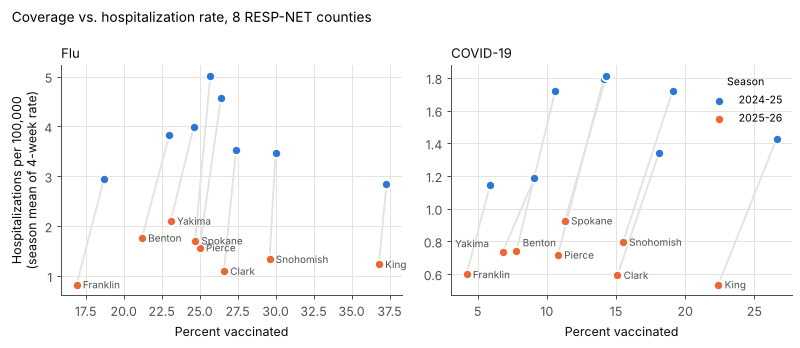

In [14]:
county_corr = corr_table(county)
print(county_corr.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
scatter_panel(axes[0], county[county["vaccine"] == "Influenza"], "Flu", logy=False)
scatter_panel(axes[1], county[county["vaccine"] == "COVID-19"], "COVID-19", logy=False,
              nudge={"Yakima": (-38, 4), "Benton": (5, 4)})
axes[0].set_ylabel("Hospitalizations per 100,000\n(season mean of 4-week rate)")
axes[1].legend(frameon=False, fontsize=8.5, title="Season", title_fontsize=8.5)
fig.suptitle("Coverage vs. hospitalization rate, 8 RESP-NET counties", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_county_scatter.png")
plt.show()

## 9. Pooled model with cross-validation

To pull the race data together, I fit a linear regression of log(hospitalization rate) on illness, season and coverage, using the flu and COVID-19 race/ethnicity rows (6 groups x 2 illnesses x 2 seasons = 24 rows). The baseline model has illness and season only.

Validation: leave-one-group-out cross-validation. Each fold holds out every row for one race/ethnicity group, fits on the other five, and predicts the held-out group. This tests whether knowing a *new* group's coverage improves the prediction of its hospitalization rate. Metric: mean absolute error (MAE) on the natural-log scale, plus the multiplicative error factor exp(MAE), so 1.70 is the geometric mean multiplicative error factor. With only six groups, validation is exploratory.

The group bootstrap samples six demographic groups with replacement 2,000 times (seed 680), retaining all rows for each selected group. The 2.5th and 97.5th percentiles of the fitted coverage coefficients form an exploratory 95% interval. With only six distinct groups, the interval may be unstable and is not evidence of a causal effect.

### 9a. Cross-validated model comparison

In [15]:
pool = race[race["vaccine"].isin(["COVID-19", "Influenza"])].copy()
if pool[["coverage", "season_rate"]].isna().any().any() or (pool["season_rate"] <= 0).any():
    raise ValueError("Regression requires complete coverage and positive rates.")
pool["log_rate"] = np.log(pool["season_rate"])
X_base = pd.get_dummies(pool[["illness", "season"]], drop_first=True).astype(float)
X_full = X_base.assign(coverage=pool["coverage"].values)
y = pool["log_rate"].values
groups = pool["label"].values

def logo_mae(X, y, groups):
    errors = []
    logo = LeaveOneGroupOut()
    for train_index, test_index in logo.split(X, y, groups):
        model = LinearRegression()
        model.fit(X.iloc[train_index], y[train_index])
        predictions = model.predict(X.iloc[test_index])
        errors.extend(np.abs(predictions - y[test_index]))
    return np.mean(errors)

results = []
for name, X in [("Baseline: illness + season", X_base), ("Full: + coverage", X_full)]:
    mae = logo_mae(X, y, groups)
    fit = LinearRegression().fit(X, y)
    results.append({"model": name, "LOGO MAE (log)": round(mae, 3), "error factor": round(np.exp(mae), 2),
                    "in-sample R2": round(fit.score(X, y), 2)})
model_table = pd.DataFrame(results)
print(model_table.to_string(index=False))

                     model  LOGO MAE (log)  error factor  in-sample R2
Baseline: illness + season           0.531          1.70          0.58
          Full: + coverage           0.637          1.89          0.66


### 9b. Coverage coefficient (primary six-group model)

In [16]:
full = LinearRegression().fit(X_full, y)
coef = full.coef_[list(X_full.columns).index("coverage")]
print(f"\nCoverage coefficient: {coef:.3f} per percentage point "
      f"-> {100*(np.exp(10*coef)-1):.0f}% estimated difference in group hospitalization rate per 10-point higher coverage")


Coverage coefficient: -0.052 per percentage point -> -40% estimated difference in group hospitalization rate per 10-point higher coverage


### 9c. Group bootstrap interval

In [17]:
rng = np.random.default_rng(680)
labels = pool["label"].unique()
boots = []
for _ in range(2000):
    sampled_groups = rng.choice(labels, size=len(labels), replace=True)
    sampled_rows = []
    for group in sampled_groups:
        sampled_rows.append(pool[pool["label"] == group])
    b = pd.concat(sampled_rows)
    Xb = pd.get_dummies(b[["illness", "season"]], drop_first=True).astype(float).assign(coverage=b["coverage"].values)
    if Xb["coverage"].nunique() > 2:
        bootstrap_model = LinearRegression()
        bootstrap_model.fit(Xb, np.log(b["season_rate"]))
        boots.append(bootstrap_model.coef_[-1])
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Bootstrap samples kept: {len(boots)} of 2000 (samples with too little coverage variation are skipped)")
print(f"Group-bootstrap 95% interval for coverage coefficient: {lo:.3f} to {hi:.3f}")

Bootstrap samples kept: 2000 of 2000 (samples with too little coverage variation are skipped)
Group-bootstrap 95% interval for coverage coefficient: -0.161 to 0.056


Sensitivity check: the same cross-validation without the Hispanic rows (the one group matched across two different classification systems).

In [18]:
keep = pool["label"] != "Hispanic"
y_no_hisp = y[keep.values]
groups_no_hisp = groups[keep.values]
sens = []
for name, X in [("Baseline: illness + season", X_base[keep.values]), ("Full: + coverage", X_full[keep.values])]:
    mae = logo_mae(X, y_no_hisp, groups_no_hisp)
    sens.append({"model": name + " (no Hispanic)", "LOGO MAE (log)": round(mae, 3), "error factor": round(np.exp(mae), 2),
                 "in-sample R2": round(LinearRegression().fit(X, y_no_hisp).score(X, y_no_hisp), 2)})
coef_nh = LinearRegression().fit(X_full[keep.values], y_no_hisp).coef_[-1]
model_table = pd.concat([model_table, pd.DataFrame(sens)], ignore_index=True)
print(model_table.to_string(index=False))
print(f"\nCoverage coefficient without Hispanic: {coef_nh:.3f} -> "
      f"{100*(np.exp(10*coef_nh)-1):.0f}% estimated group-rate difference per 10-point higher coverage")

                                   model  LOGO MAE (log)  error factor  in-sample R2
              Baseline: illness + season           0.531          1.70          0.58
                        Full: + coverage           0.637          1.89          0.66
Baseline: illness + season (no Hispanic)           0.591          1.81          0.57
          Full: + coverage (no Hispanic)           0.378          1.46          0.88

Coverage coefficient without Hispanic: -0.127 -> -72% estimated group-rate difference per 10-point higher coverage


## 10. Priority groups: coverage gap vs. burden (Figure 5)

For each group and illness in 2025-26: x = coverage minus the statewide coverage (percentage points), y = hospitalization rate ratio vs. the RESP-NET overall rate. Groups in the lower-coverage, higher-burden corner are potential outreach priorities, not evidence that outreach will reduce hospitalizations.

  vaccine    label  coverage  cov_gap  season_rate  rate_ratio
 COVID-19    AI/AN      12.0     -3.3         0.56        0.85
 COVID-19    Asian      14.7     -0.6         0.29        0.44
 COVID-19    Black       9.8     -5.5         0.72        1.09
 COVID-19 Hispanic       5.3    -10.0         0.46        0.70
 COVID-19    NH/PI       7.7     -7.6         1.49        2.25
 COVID-19    White      16.9      1.6         0.55        0.83
Influenza    AI/AN      26.7     -2.4         1.22        0.88
Influenza    Asian      34.3      5.2         0.71        0.51
Influenza    Black      22.5     -6.6         2.15        1.55
Influenza Hispanic      18.1    -11.0         1.06        0.76
Influenza    NH/PI      22.7     -6.4         5.06        3.64
Influenza    White      28.3     -0.8         1.07        0.77


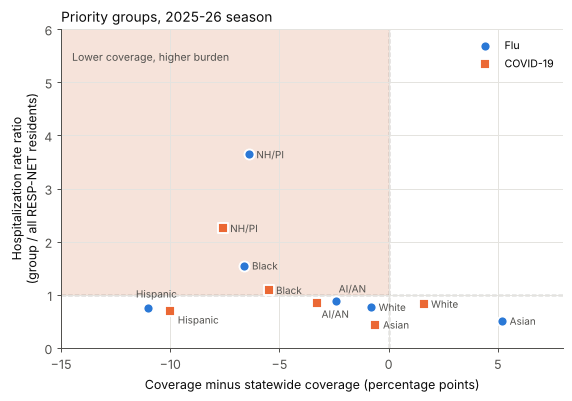

In [19]:
overall = resp[(resp["category"] == "Overall")].set_index(["illness", "season"])["season_rate"]
pri = race[race["vaccine"].isin(["COVID-19", "Influenza"]) & (race["season"] == SEASONS[1])].copy()
pri["state_cov"] = pri["vaccine"].map(statewide.loc[SEASONS[1]])
pri["cov_gap"] = pri["coverage"] - pri["state_cov"]
pri["rate_ratio"] = pri.apply(lambda r: r["season_rate"] / overall[(r["illness"], r["season"])], axis=1)
print(pri[["vaccine", "label", "coverage", "cov_gap", "season_rate", "rate_ratio"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.axhline(1, color=INK2, lw=1, ls="--", zorder=1)
ax.axvline(0, color=INK2, lw=1, ls="--", zorder=1)
ax.fill_between([-15, 0], 1, 6, color="#f6e3da", zorder=0)
ax.text(-14.5, 5.6, "Lower coverage, higher burden", fontsize=8.5, color=INK2, va="top")
for vax, col, mk in [("Influenza", C_BLUE, "o"), ("COVID-19", C_ORANGE, "s")]:
    d = pri[pri["vaccine"] == vax]
    ax.scatter(d["cov_gap"], d["rate_ratio"], s=65, color=col, marker=mk, edgecolor="white",
               linewidth=1.5, zorder=3, label="Flu" if vax == "Influenza" else vax)
    for _, r in d.iterrows():
        off = {("Influenza", "Hispanic"): (-10, 8), ("COVID-19", "Hispanic"): (6, -10),
               ("Influenza", "AI/AN"): (2, 7), ("COVID-19", "AI/AN"): (4, -12)}.get((vax, r["label"]), (6, -3))
        ax.annotate(r["label"], (r["cov_gap"], r["rate_ratio"]), textcoords="offset points",
                    xytext=off, fontsize=8, color=INK2)
ax.set_xlim(-15, 8); ax.set_ylim(0, 6)
ax.set_xlabel("Coverage minus statewide coverage (percentage points)")
ax.set_ylabel("Hospitalization rate ratio\n(group / all RESP-NET residents)")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.set_title("Priority groups, 2025-26 season", loc="left", fontsize=11, color=INK)
fig.savefig(f"{FIG_DIR}/fig5_priority_matrix.png")
plt.show()